In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import os
import time
from mpl_toolkits.mplot3d import Axes3D 
import scipy
import sys

In [2]:
import gymnasium
from gymnasium import spaces

In [3]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common import results_plotter
import autograd, autograd.core, autograd.extend, autograd.tracer  
import autograd.numpy as anp 
from deap import base
from deap import creator
from deap import tools
import random
import seaborn as sns
import gudhi as gd
from stable_baselines3.common.vec_env import SubprocVecEnv, VecMonitor
from pathos.multiprocessing import ProcessingPool as Pool

In [4]:
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

In [5]:
sys.path.append('../../../../../../../ocean_intella/ocean_intella/pipelay_profile_optimization/')

In [6]:
import elitism

In [7]:
x0, y0 = 44, 44

### Finite Element Model

In [8]:
class ObjectView(object):
    def __init__(self, d): self.__dict__ = d
    
def get_args(normals, forces, density=1e-4):  # Manage the problem setup parameters
    width = normals.shape[0] - 1
    height = normals.shape[1] - 1
    fixdofs = np.flatnonzero(normals.ravel())
    alldofs = np.arange(2 * (width + 1) * (height + 1))
    freedofs = np.sort(list(set(alldofs) - set(fixdofs)))
    params = {
      # material properties
      'young': 1, 'young_min': 1e-9, 'poisson': 0.3, 'g': 0,
      # constraints
      'density': density, 'xmin': 0.001, 'xmax': 1.0,
      # input parameters
      'nelx': width, 'nely': height, 'mask': 1, 'penal': 3.0, 'filter_width': 1,
      'freedofs': freedofs, 'fixdofs': fixdofs, 'forces': forces.ravel(),
      # optimization parameters
      'opt_steps': 80, 'print_every': 10}
#     print(params)
    return ObjectView(params)

def mbb_beam(width=y0, height=x0, density=1e-4, y=1, x=0, rd=0):  # textbook beam example
    normals = np.zeros((width + 1, height + 1, 2))
    normals[0, 0, x] = 1
    normals[0, 0, y] = 1
    normals[0, -1, x] = 1
    normals[0, -1, y] = 1
    forces = np.zeros((width + 1, height + 1, 2))
    forces[-1, rd, y] = 1
    return normals, forces, density

In [9]:
def young_modulus(x, e_0, e_min, p=3):
    return e_min + x ** p * (e_0 - e_min)

def physical_density(x, args, volume_contraint=False, use_filter=True):
    x = args.mask * x.reshape(args.nely, args.nelx)  # reshape from 1D to 2D
    return gaussian_filter(x, args.filter_width) if use_filter else x  # maybe filter

def mean_density(x, args, volume_contraint=False, use_filter=True):
    return anp.mean(physical_density(x, args, volume_contraint, use_filter)) / anp.mean(args.mask)

In [10]:
def objective(x, args, volume_contraint=False, use_filter=True):
    kwargs = dict(penal=args.penal, e_min=args.young_min, e_0=args.young)
    x_phys = physical_density(x, args, volume_contraint=volume_contraint, use_filter=use_filter)
    ke     = get_stiffness_matrix(args.young, args.poisson)  # stiffness matrix
    u      = displace(x_phys, ke, args.forces, args.freedofs, args.fixdofs, **kwargs)
    c      = compliance(x_phys, u, ke, **kwargs)
    return c

In [11]:
def gaussian_filter(x, width): # 2D gaussian blur/filter
    return scipy.ndimage.gaussian_filter(x, width, mode='reflect')

def _gaussian_filter_vjp(ans, x, width): # gives the gradient of orig. function w.r.t. x
    del ans, x  # unused
    return lambda g: gaussian_filter(g, width)

In [12]:
def compliance(x_phys, u, ke, *, penal=3, e_min=1e-9, e_0=1):
    nely, nelx = x_phys.shape
    ely, elx = anp.meshgrid(range(nely), range(nelx))  # x, y coords for the index map

    n1 = (nely+1)*(elx+0) + (ely+0)  # nodes
    n2 = (nely+1)*(elx+1) + (ely+0)
    n3 = (nely+1)*(elx+1) + (ely+1)
    n4 = (nely+1)*(elx+0) + (ely+1)
    all_ixs = anp.array([2*n1, 2*n1+1, 2*n2, 2*n2+1, 2*n3, 2*n3+1, 2*n4, 2*n4+1])
    u_selected = u[all_ixs]  # select from u matrix

    ke_u = anp.einsum('ij,jkl->ikl', ke, u_selected)  # compute x^penal * U.T @ ke @ U
    ce = anp.einsum('ijk,ijk->jk', u_selected, ke_u)
    C = young_modulus(x_phys, e_0, e_min, p=penal) * ce.T
    return anp.sum(C)

def get_stiffness_matrix(e, nu):  # e=young's modulus, nu=poisson coefficient
    k = anp.array([1/2-nu/6, 1/8+nu/8, -1/4-nu/12, -1/8+3*nu/8,
                -1/4+nu/12, -1/8-nu/8, nu/6, 1/8-3*nu/8])
    return e/(1-nu**2)*anp.array([[k[0], k[1], k[2], k[3], k[4], k[5], k[6], k[7]],
                               [k[1], k[0], k[7], k[6], k[5], k[4], k[3], k[2]],
                               [k[2], k[7], k[0], k[5], k[6], k[3], k[4], k[1]],
                               [k[3], k[6], k[5], k[0], k[7], k[2], k[1], k[4]],
                               [k[4], k[5], k[6], k[7], k[0], k[1], k[2], k[3]],
                               [k[5], k[4], k[3], k[2], k[1], k[0], k[7], k[6]],
                               [k[6], k[3], k[4], k[1], k[2], k[7], k[0], k[5]],
                               [k[7], k[2], k[1], k[4], k[3], k[6], k[5], k[0]]])

In [13]:
def get_k(stiffness, ke):
    # Constructs sparse stiffness matrix k (used in the displace fn)
    # First, get position of the nodes of each element in the stiffness matrix
    nely, nelx = stiffness.shape
    ely, elx = anp.meshgrid(range(nely), range(nelx))  # x, y coords
    ely, elx = ely.reshape(-1, 1), elx.reshape(-1, 1)

    n1 = (nely+1)*(elx+0) + (ely+0)
    n2 = (nely+1)*(elx+1) + (ely+0)
    n3 = (nely+1)*(elx+1) + (ely+1)
    n4 = (nely+1)*(elx+0) + (ely+1)
    edof = anp.array([2*n1, 2*n1+1, 2*n2, 2*n2+1, 2*n3, 2*n3+1, 2*n4, 2*n4+1])
    edof = edof.T[0]
    x_list = anp.repeat(edof, 8)  # flat list pointer of each node in an element
    y_list = anp.tile(edof, 8).flatten()  # flat list pointer of each node in elem

    # make the global stiffness matrix K
    kd = stiffness.T.reshape(nelx*nely, 1, 1)
    value_list = (kd * anp.tile(ke, kd.shape)).flatten()
    return value_list, y_list, x_list

def displace(x_phys, ke, forces, freedofs, fixdofs, *, penal=3, e_min=1e-9, e_0=1):
    # Displaces the load x using finite element techniques (solve_coo=most of runtime)
    stiffness = young_modulus(x_phys, e_0, e_min, p=penal)
    k_entries, k_ylist, k_xlist = get_k(stiffness, ke)

    index_map, keep, indices = _get_dof_indices(freedofs, fixdofs, k_ylist, k_xlist)

    u_nonzero = solve_coo(k_entries[keep], indices, forces[freedofs], sym_pos=True)
    u_values = anp.concatenate([u_nonzero, anp.zeros(len(fixdofs))])
    return u_values[index_map]

In [14]:
def _get_dof_indices(freedofs, fixdofs, k_xlist, k_ylist):
    index_map = inverse_permutation(anp.concatenate([freedofs, fixdofs]))
    keep = anp.isin(k_xlist, freedofs) & anp.isin(k_ylist, freedofs)
    # Now we index an indexing array that is being indexed by the indices of k
    i = index_map[k_ylist][keep]
    j = index_map[k_xlist][keep]
    return index_map, keep, anp.stack([i, j])

def inverse_permutation(indices):  # reverses an index operation
    inverse_perm = np.zeros(len(indices), dtype=anp.int64)
    inverse_perm[indices] = np.arange(len(indices), dtype=anp.int64)
    return inverse_perm

In [15]:
def _get_solver(a_entries, a_indices, size, sym_pos):
    # a is (usu.) symmetric positive; could solve 2x faster w/sksparse.cholmod.cholesky(a).solve_A
    a = scipy.sparse.coo_matrix((a_entries, a_indices), shape=(size,)*2).tocsc()
    return scipy.sparse.linalg.splu(a).solve


def solve_coo(a_entries, a_indices, b, sym_pos=False):
    solver = _get_solver(a_entries, a_indices, b.size, sym_pos)
    return solver(b)

def grad_solve_coo_entries(ans, a_entries, a_indices, b, sym_pos=False):
    def jvp(grad_ans):
        lambda_ = solve_coo(a_entries, a_indices if sym_pos else a_indices[::-1],
                            grad_ans, sym_pos)
        i, j = a_indices
        return -lambda_[i] * ans[j]
    return jvp

In [16]:
def fast_stopt(args, x):

    reshape = lambda x: x.reshape(args.nely, args.nelx)
    objective_fn = lambda x: objective(reshape(x), args)
#     constraint = lambda params: mean_density(reshape(params), args) - args.density
    constraint = lambda params: mean_density(reshape(params), args) 
    value = objective_fn(x)
    const = constraint(x)
    return value, const

In [17]:
def draw(X):  
    plt.figure(dpi=50) 
    print('\nFinal Cantilever beam design:')
    plt.imshow(X) 
    plt.show()

### Genetic Modelling

In [18]:
# Genetic Algorithm constants:
POPULATION_SIZE = 300
P_CROSSOVER = 0.9  # probability for crossover
P_MUTATION = 0.1   # probability for mutating an individual
MAX_GENERATIONS = 2000
HALL_OF_FAME_SIZE = 30

In [19]:
PENALTY_VALUE = 1000.0 

In [20]:
# set the random seed:
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

In [21]:
toolbox = base.Toolbox()

In [22]:
# define a single objective, minimizing fitness strategy:
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))

In [23]:
# create the Individual class based on list:
creator.create("Individual", list, fitness=creator.FitnessMin)

In [24]:
# create an operator that randomly returns 0 or 1:
toolbox.register("zeroOrOne", random.randint, 0, 1)

In [25]:
# create the individual operator to fill up an Individual instance:
toolbox.register("individualCreator", 
                 tools.initRepeat,
                 creator.Individual,
                 toolbox.zeroOrOne, 
                 x0*y0+4)

In [26]:
# create the population operator to generate a list of individuals:
toolbox.register("populationCreator", 
                 tools.initRepeat, 
                 list, 
                 toolbox.individualCreator)

In [27]:
# convert a binary list to decimal
def binatodeci(binary):
    return sum(val*(2**idx) for idx, val in enumerate(reversed(binary)))

In [28]:
class Prev:
    def __init__(self):
        self.prev = 100

In [29]:
T=Prev()

In [30]:
# fitness calculation
def staticFEM(individual):
    
    args = get_args(*mbb_beam(rd=0))
    
    x = np.array([t if t==1 else 1e-4 for t in individual[:-4]]) 
    
    
    try:
        if np.sum(x)/(x0*y0) > 0.5:
            tmp, const = fast_stopt(args, x)
            T.prev=tmp
            if const>(55+binatodeci(individual[-4:]))/100:
                return PENALTY_VALUE, 
        else:
            return T.prev,
    except:
        return PENALTY_VALUE, 
    
    
    return tmp,  # return a tuple

In [31]:
toolbox.register("evaluate", staticFEM)
pool = Pool(8)
toolbox.register("map", pool.map)

# genetic operators:
toolbox.register("select", tools.selTournament, tournsize=2)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=1.0/(x0*y0+4))

/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/multiprocess/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/multiprocess/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


In [32]:
# Genetic Algorithm flow:
def main():

    # create initial population (generation 0):
    population = toolbox.populationCreator(n=POPULATION_SIZE)

    # prepare the statistics object:
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("min", np.min)
    stats.register("avg", np.mean)

    # define the hall-of-fame object:
    hof = tools.HallOfFame(HALL_OF_FAME_SIZE)

    # perform the Genetic Algorithm flow with hof feature added:
    population, logbook = elitism.eaSimpleWithElitism(population, toolbox, cxpb=P_CROSSOVER, mutpb=P_MUTATION,
                                              ngen=MAX_GENERATIONS, stats=stats, halloffame=hof, verbose=True)

    # print best solution found:
    best = hof.items[0]
    print("-- Best Individual = ", best)
    print("-- Best Fitness = ", best.fitness.values[0])
    print()
    
    x = np.array(best[:-4]).astype(np.float64).reshape(x0,y0)
    
    args = get_args(*mbb_beam(rd=0))
    print(fast_stopt(args, x))
    
    draw(x)
    

    # extract statistics:
    minFitnessValues, meanFitnessValues = logbook.select("min", "avg")

    # plot statistics:
    sns.set_style("whitegrid")
    plt.plot(minFitnessValues, color='red')
    plt.plot(meanFitnessValues, color='green')
  
    plt.xlabel('Generation')
    plt.ylabel('Min / Average Fitness')
    plt.title('Min and Average fitness over Generations')
    plt.show()    
    return x

gen	nevals	min	avg    
0  	300   	100	52815.6
1  	238   	100	103262 
2  	255   	100	141067 
3  	246   	100	1176.88
4  	242   	100	99457.6
5  	240   	100	204757 
6  	247   	100	204953 
7  	233   	100	1587.54
8  	248   	100	1596.78
9  	248   	100	206039 
10 	255   	100	103265 
11 	246   	97.6618	101826 
12 	242   	97.6618	101718 
13 	237   	97.6618	102863 
14 	241   	93.9478	305711 
15 	252   	92.6668	407373 
16 	225   	90.8632	103351 
17 	249   	89.1212	98.0783
18 	251   	82.7899	95.3342
19 	252   	82.7899	99.2393
20 	235   	82.7668	97.3133
21 	247   	82.5686	95.69  
22 	240   	78.7442	99.3986
23 	236   	78.7442	100.751
24 	247   	78.1738	111.588
25 	230   	77.1155	97.8985
26 	246   	76.2506	102.846
27 	240   	75.102 	92.6446
28 	251   	72.6021	94.539 
29 	247   	71.6131	93.4244
30 	249   	71.6131	76.9836
31 	247   	68.8302	75.8039
32 	245   	68.457 	74.5419
33 	256   	67.7475	73.4133
34 	257   	64.0496	71.8364
35 	251   	64.0496	70.3424
36 	251   	64.0496	69.0068
37 	231   	63.8907	67.

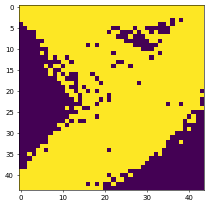

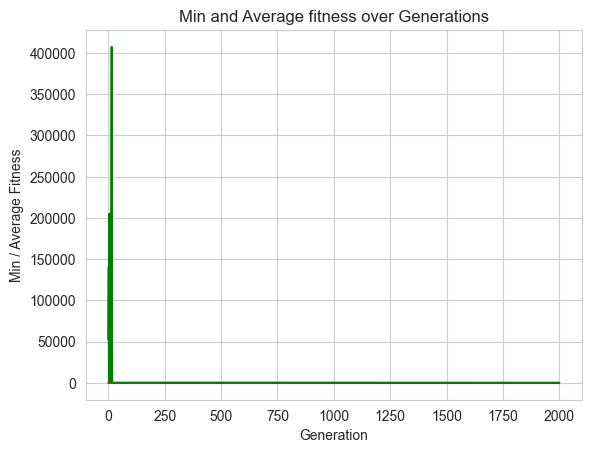

In [33]:
if __name__ == "__main__":
    start = time.time()
    top_ = main()
    end = time.time()


Final Cantilever beam design:


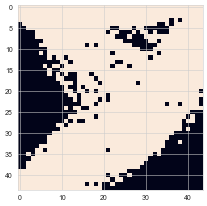

In [34]:
draw(top_)

### GA-pt-RL-pbr: parallel block refinement (RL)

Stage 2 of the strategy. The GA topology (`ga_grid`) is the **frozen background**. The grid is divided into `BLOCKS_PER_SIDE x BLOCKS_PER_SIDE` blocks (4 x 4 = 16 blocks of 8 x 8 for a 32 x 32 grid). For every block there is one environment in which:

* the block **starts from its GA content**,
* the agent **flips cells inside that block only** (add or remove material),
* **all other blocks stay frozen at the GA topology**,
* the reward is the improvement of the compliance of the whole grid (only this block changed), under the GA design's volume.

The 16 block environments run **in parallel** (`SubprocVecEnv`). One PPO policy trains on all of them; it is told which block it is working on (one-hot block id in the observation). After training, the refined blocks are merged and the merged design is **verified by FEM** against the GA design.

In [35]:
# keep the GA pre-training result (it is the expensive part)
# np.save('ga_topology.npy', np.asarray(top_))
# next time, to skip the GA stage:  top_ = np.load('ga_topology.npy')

In [36]:
# ---------------- block layout ----------------
BLOCKS_PER_SIDE = 4                          # 4 x 4 = 16 blocks (28x28 -> 7x7 blocks works the same way)
N_BLOCKS = BLOCKS_PER_SIDE ** 2
assert x0 % BLOCKS_PER_SIDE == 0 and y0 % BLOCKS_PER_SIDE == 0
BX, BY = x0 // BLOCKS_PER_SIDE, y0 // BLOCKS_PER_SIDE    # block size, 8 x 8 for a 32 x 32 grid
VOID = 1e-4

# ---------------- refinement settings ----------------
EPISODE_STEPS = (BX * BY) // 2               # cell flips per episode
VOL_TOL = 0.0                                # allowed relative volume excess over the GA design
VOL_PENALTY = 10.0                           # weight of the volume-constraint penalty in the objective
REWARD_SCALE = 10.0                          # scales the (small) per-step compliance improvements

# frozen background = GA pre-training result (void -> 1e-4, solid -> 1)
ga_grid = np.where(np.asarray(top_) == 0, VOID, 1.0).astype(np.float64)


def block_slice(b):
    """Row/column slices of block b (row-major block numbering)."""
    r, c = divmod(b, BLOCKS_PER_SIDE)
    return slice(r * BX, (r + 1) * BX), slice(c * BY, (c + 1) * BY)


def insert_block(grid, block, b):
    """Copy of `grid` with block b replaced by `block` (everything else untouched)."""
    out = grid.copy()
    out[block_slice(b)] = block
    return out


_FEM_ARGS = {}


def evaluate(grid):
    """FEM compliance and mean density of a full (x0, y0) grid. Returns (inf, vol) if the FEM solve fails."""
    if 'args' not in _FEM_ARGS:                      # built once per process
        _FEM_ARGS['args'] = get_args(*mbb_beam(rd=0))
    try:
        c, vol = fast_stopt(_FEM_ARGS['args'], grid)
        c, vol = float(c), float(vol)
        if not np.isfinite(c):
            return np.inf, vol
        return c, vol
    except Exception:
        return np.inf, float(np.mean(grid))


# GA baseline: this is what the refinement has to beat, at the same (or lower) volume
c_ga, vol_ga = evaluate(ga_grid)
VOL_LIMIT = vol_ga * (1.0 + VOL_TOL)
print('GA baseline: compliance = %.4f, volume = %.4f' % (c_ga, vol_ga))

GA baseline: compliance = 23.9592, volume = 0.6999


In [37]:
class BlockRefineEnv(gymnasium.Env):
    """Refine ONE block of the GA topology; every other block stays frozen at the GA topology.

    state       : the block, initialised from the GA block at every reset
    action      : flip one cell of the block (solid <-> void)
    observation : the whole grid (GA background + current block) as 0/1, one-hot block id, time fraction
    reward      : improvement of  J = compliance / GA compliance + penalty * volume excess   (J_prev - J_new)
                  -> the episode return is the total improvement over the GA design
    """
    metadata = {"render_modes": []}

    def __init__(self, block_id, ga_grid, c_ref, vol_limit, episode_steps=EPISODE_STEPS,
                 vol_penalty=VOL_PENALTY, reward_scale=REWARD_SCALE):
        super().__init__()
        self.b = int(block_id)
        self.ga_grid = np.array(ga_grid, dtype=np.float64)
        self.sl = block_slice(self.b)
        self.ga_block = self.ga_grid[self.sl].copy()
        self.c_ref, self.vol_limit = float(c_ref), float(vol_limit)
        self.episode_steps = int(episode_steps)
        self.vol_penalty, self.reward_scale = float(vol_penalty), float(reward_scale)

        self.action_space = spaces.Discrete(BX * BY)
        self.observation_space = spaces.Box(0.0, 1.0, shape=(x0 * y0 + N_BLOCKS + 1,), dtype=np.float32)

        c0, v0 = evaluate(self.ga_grid)
        self.J0 = self._objective(c0, v0)          # = 1.0 for the GA design itself
        # best FEASIBLE block seen so far; survives resets, starts as the GA block (so it is never worse than GA)
        self.best_J, self.best_block = self.J0, self.ga_block.copy()
        self.block, self.J, self.t = self.ga_block.copy(), self.J0, 0

    def _objective(self, c, vol):
        return c / self.c_ref + self.vol_penalty * max(0.0, vol / self.vol_limit - 1.0)

    def _obs(self, grid):
        onehot = np.zeros(N_BLOCKS, dtype=np.float32)
        onehot[self.b] = 1.0
        return np.concatenate([(grid > 0.5).ravel().astype(np.float32), onehot,
                               np.array([self.t / self.episode_steps], dtype=np.float32)])

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.block = self.ga_block.copy()          # start from the GA content of this block
        self.J, self.t = self.J0, 0
        return self._obs(insert_block(self.ga_grid, self.block, self.b)), {}

    def step(self, action):
        r, c = divmod(int(action), BY)
        old = self.block[r, c]
        self.block[r, c] = 1.0 if old < 0.5 else VOID      # flip: add or remove material
        grid = insert_block(self.ga_grid, self.block, self.b)   # all other blocks = GA topology
        comp, vol = evaluate(grid)
        self.t += 1

        if not np.isfinite(comp):                  # FEM failed -> undo the flip, small penalty
            self.block[r, c] = old
            reward = -1.0
            grid = insert_block(self.ga_grid, self.block, self.b)
        else:
            J = self._objective(comp, vol)
            reward = self.reward_scale * (self.J - J)
            self.J = J
            if vol <= self.vol_limit * (1.0 + 1e-9) and J < self.best_J:
                self.best_J, self.best_block = J, self.block.copy()

        truncated = self.t >= self.episode_steps
        return self._obs(grid), float(reward), False, truncated, {}

    def get_best(self):
        return {"block_id": self.b, "block": self.best_block.copy(), "J": float(self.best_J)}


def merge_refined_blocks(best_list):
    """Combine the refined blocks.
    naive    : insert all refined blocks at once (blocks interact, so this can be worse than GA)
    verified : insert block by block, most promising first, and keep a block only if the WHOLE grid
               stays within the volume limit and its compliance really decreases."""
    naive = ga_grid.copy()
    for d in best_list:
        naive[block_slice(d["block_id"])] = d["block"]

    merged, c_cur, accepted = ga_grid.copy(), c_ga, []
    for d in sorted(best_list, key=lambda d: d["J"]):
        cand = insert_block(merged, d["block"], d["block_id"])
        c_new, vol_new = evaluate(cand)
        if vol_new <= VOL_LIMIT * (1.0 + 1e-9) and c_new < c_cur:
            merged, c_cur = cand, c_new
            accepted.append(d["block_id"])
    return naive, merged, accepted

In [38]:
# sanity check of a single block environment
check_env(BlockRefineEnv(0, ga_grid, c_ga, VOL_LIMIT))

### Training (16 blocks in parallel)

In [39]:
ts = int(1e6)          # total PPO timesteps, summed over all 16 block environments
START_METHOD = "fork" if sys.platform.startswith("linux") else None   # None -> stable-baselines3 default

In [40]:
def make_block_env(b):
    def _init():
        return BlockRefineEnv(b, ga_grid, c_ga, VOL_LIMIT)
    return _init

# 16 block environments, each in its own process = the blocks are refined in parallel
venv = SubprocVecEnv([make_block_env(b) for b in range(N_BLOCKS)], start_method=START_METHOD)
venv = VecMonitor(venv)

start = time.time()
model = PPO("MlpPolicy", venv, device="cpu", n_steps=2 * EPISODE_STEPS, batch_size=256, n_epochs=5,
            gamma=0.995, ent_coef=0.01, verbose=1).learn(total_timesteps=ts)
end = time.time()
# model.save('block_refine_ppo')

















/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/stable_baselines3/ppo/ppo.py:155: UserWarning: You have specified a mini-batch size of 256, but because the `RolloutBuffer` is of size `n_steps * n_envs = 1920`, after every 7 untruncated mini-batches, there will be a truncated mini-batch of size 128
We recommend using a `batch_size` that is a factor of `n_steps * n_envs`.
Info: (n_steps=120 and n_envs=16)
  warnings.warn(


Using cpu device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 60       |
|    ep_rew_mean     | -1.4     |
| time/              |          |
|    fps             | 283      |
|    iterations      | 1        |
|    time_elapsed    | 6        |
|    total_timesteps | 1920     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 60          |
|    ep_rew_mean          | -1.62       |
| time/                   |             |
|    fps                  | 283         |
|    iterations           | 2           |
|    time_elapsed         | 13          |
|    total_timesteps      | 3840        |
| train/                  |             |
|    approx_kl            | 0.010640018 |
|    clip_fraction        | 0.0637      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.79       |
|    explained_variance   | 0.000946    |
|    learning

In [41]:
print('Total time taken: {} min'.format((end - start)/60))

Total time taken: 65.06529281536739 min


### Merge and verification

In [42]:
# deterministic roll-out of the trained policy in every block environment
# (each environment also keeps the best feasible block it has seen during training)
obs = venv.reset()
for _ in range(EPISODE_STEPS):
    actions, _ = model.predict(obs, deterministic=True)
    obs, _, _, _ = venv.step(actions)

best_blocks = venv.env_method("get_best")
for d in best_blocks:
    print('block %2d: best J = %.4f' % (d["block_id"], d["J"]))

block  0: best J = 1.0000
block  1: best J = 1.0000
block  2: best J = 0.9998
block  3: best J = 0.9998
block  4: best J = 0.9999
block  5: best J = 0.9998
block  6: best J = 0.9999
block  7: best J = 1.0000
block  8: best J = 0.9998
block  9: best J = 0.9997
block 10: best J = 1.0000
block 11: best J = 0.9995
block 12: best J = 0.9998
block 13: best J = 0.9998
block 14: best J = 0.9999
block 15: best J = 1.0000


In [43]:
# merge the refined blocks and verify the result with FEM
naive_grid, merged_grid, accepted = merge_refined_blocks(best_blocks)
c_naive, vol_naive = evaluate(naive_grid)
c_mrg, vol_mrg = evaluate(merged_grid)

print('GA only            : compliance = %.4f  volume = %.4f' % (c_ga, vol_ga))
print('naive merge        : compliance = %.4f  volume = %.4f' % (c_naive, vol_naive))
print('verified merge     : compliance = %.4f  volume = %.4f   (blocks kept: %s)' % (c_mrg, vol_mrg, sorted(accepted)))
print('improvement over GA: %.2f %%' % (100.0 * (c_ga - c_mrg) / c_ga))

grid = (merged_grid > 0.5).astype(int)      # final design (used by the topology cells below)

GA only            : compliance = 23.9592  volume = 0.6999
naive merge        : compliance = 23.9024  volume = 0.6999
verified merge     : compliance = 23.9024  volume = 0.6999   (blocks kept: [0, 1, 2, 3, 4, 5, 6, 8, 9, 11, 12, 13, 14])
improvement over GA: 0.24 %


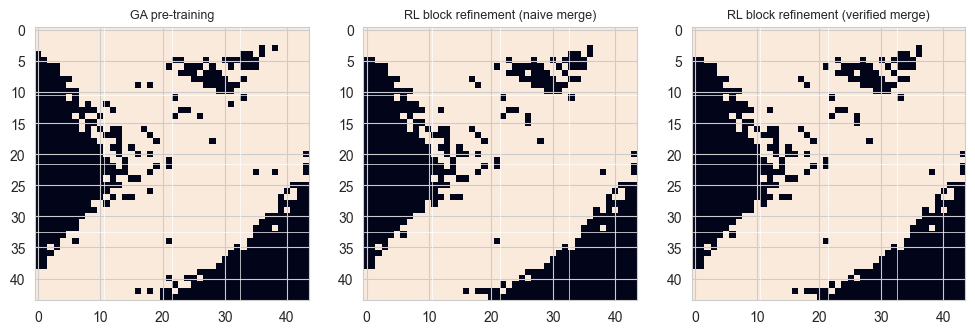

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, g, ttl in zip(axs, [ga_grid, naive_grid, merged_grid],
                      ['GA pre-training', 'RL block refinement (naive merge)', 'RL block refinement (verified merge)']):
    ax.imshow(g > 0.5)
    ax.set_title(ttl, fontsize=9)
    for k in range(1, BLOCKS_PER_SIDE):                        # block boundaries
        ax.axhline(k * BX - 0.5, color='w', lw=0.5)
        ax.axvline(k * BY - 0.5, color='w', lw=0.5)
plt.show()

In [45]:
arr = grid

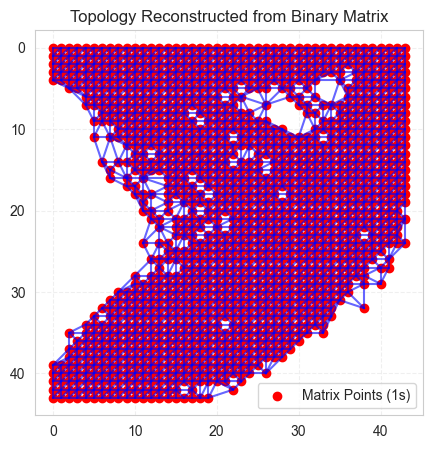

Topological Features found:
Hole/Loop exists from radius 0.25 to 4.566115702479337
Hole/Loop exists from radius 0.5 to 3.3163265306122502
Hole/Loop exists from radius 0.5 to 2.5000000000000004
Hole/Loop exists from radius 1.0 to 2.5
Hole/Loop exists from radius 0.25 to 1.25
Hole/Loop exists from radius 0.25 to 1.25
Hole/Loop exists from radius 0.25 to 1.25
Hole/Loop exists from radius 0.25 to 1.25
Hole/Loop exists from radius 0.5 to 1.3888888888888915
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.5 to 1.25
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.25 to 1.0
Hole/Loop exists from radius 0.5 to 1.25
Hole/Loop e

In [46]:
# 1. Convert Matrix to Point Cloud
# np.argwhere finds indices where value is 1
points = np.argwhere(arr == 1)

# 2. Build the Alpha Complex
# This reconstructs the topological structure from the discrete points
alpha_complex = gd.AlphaComplex(points=points)
simplex_tree = alpha_complex.create_simplex_tree()

# 3. Visualization
plt.figure(figsize=(5, 5))

# Plot the original matrix points
plt.scatter(points[:, 1], points[:, 0], c='red', label='Matrix Points (1s)')

# Reconstruct and plot the edges (1-simplices)
# Adjust alpha_threshold to "connect" points at different distances
alpha_threshold = 3
for simplex, filtration in simplex_tree.get_skeleton(1):
    if len(simplex) == 2 and filtration < alpha_threshold:
        p1, p2 = points[simplex[0]], points[simplex[1]]
        # Note: argwhere returns (row, col), so we plot (col, row) for (x, y)
        plt.plot([p1[1], p2[1]], [p1[0], p2[0]], 'b-', alpha=0.6)

plt.gca().invert_yaxis() # Match matrix coordinate system (top-down)
plt.title("Topology Reconstructed from Binary Matrix")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

# 4. Extract Topological Invariants
persistence = simplex_tree.persistence()
print("Topological Features found:")
for dim, (birth, death) in persistence:
    feature_type = "Component" if dim == 0 else "Hole/Loop"
    print(f"{feature_type} exists from radius {birth} to {death}")

In [47]:
pool.close()   
pool.join()